<a href="https://colab.research.google.com/github/fadeeva/quant_finance_projects/blob/main/01_Analysis_and_Modeling_of_Stock_Returns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analysis and Modeling of Stock Returns

In [1]:
! pip install -q arch

In [2]:
import numpy as np
import pandas as pd

import datetime as dt
import yfinance as yf

from scipy import stats

from arch import arch_model

import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [3]:
rng = np.random.default_rng(42)

## Get Data

In [4]:
tickers  = ['AAPL', 'AMZN', 'GOOGL', 'SPY', 'NVDA']

data = yf.download(
    tickers,
    dt.datetime(2021, 1, 1), dt.datetime.now(),
    auto_adjust=True
)
close = data['Close']

close.head()

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,GOOGL,NVDA,SPY
Date,,,,,
2021-01-04,125.537086,159.331497,85.492973,13.046197,341.588654
2021-01-05,127.089211,160.925507,86.182411,13.335952,343.941406
2021-01-06,122.811203,156.919006,85.332008,12.549760,345.997589
2021-01-07,127.001907,158.108002,87.880753,13.275514,351.138336
2021-01-08,128.098129,159.134995,89.044182,13.208608,353.138977


In [5]:
df = close.copy()

## Log Returns

$$
r_t = ln(\frac{p_t}{p_{t-1}})
$$

In [6]:
df = pd.concat([df, np.log(df / df.shift(1)).add_suffix('_log_ret')], axis=1)
df = df.dropna()
df.head()

Ticker,AAPL,AMZN,GOOGL,NVDA,SPY,AAPL_log_ret,AMZN_log_ret,GOOGL_log_ret,NVDA_log_ret,SPY_log_ret
Date,,,,,,,,,,
2021-01-05,127.089211,160.925507,86.182411,13.335952,343.941406,0.012288,0.009955,0.008032,0.021967,0.006864
2021-01-06,122.811203,156.919006,85.332008,12.549760,345.997589,-0.034241,-0.025212,-0.009916,-0.060762,0.005960
2021-01-07,127.001907,158.108002,87.880753,13.275514,351.138336,0.033554,0.007549,0.029431,0.056220,0.014748
2021-01-08,128.098129,159.134995,89.044182,13.208608,353.138977,0.008595,0.006475,0.013152,-0.005053,0.005681
2021-01-11,125.119972,155.710495,86.986755,13.551589,350.758453,-0.023524,-0.021754,-0.023377,0.025635,-0.006764


### Cummulative Returns Visualization

$$
R^{cumm}_T = e^{\sum^T_{t=1}{r^{log}_t}} - 1
$$

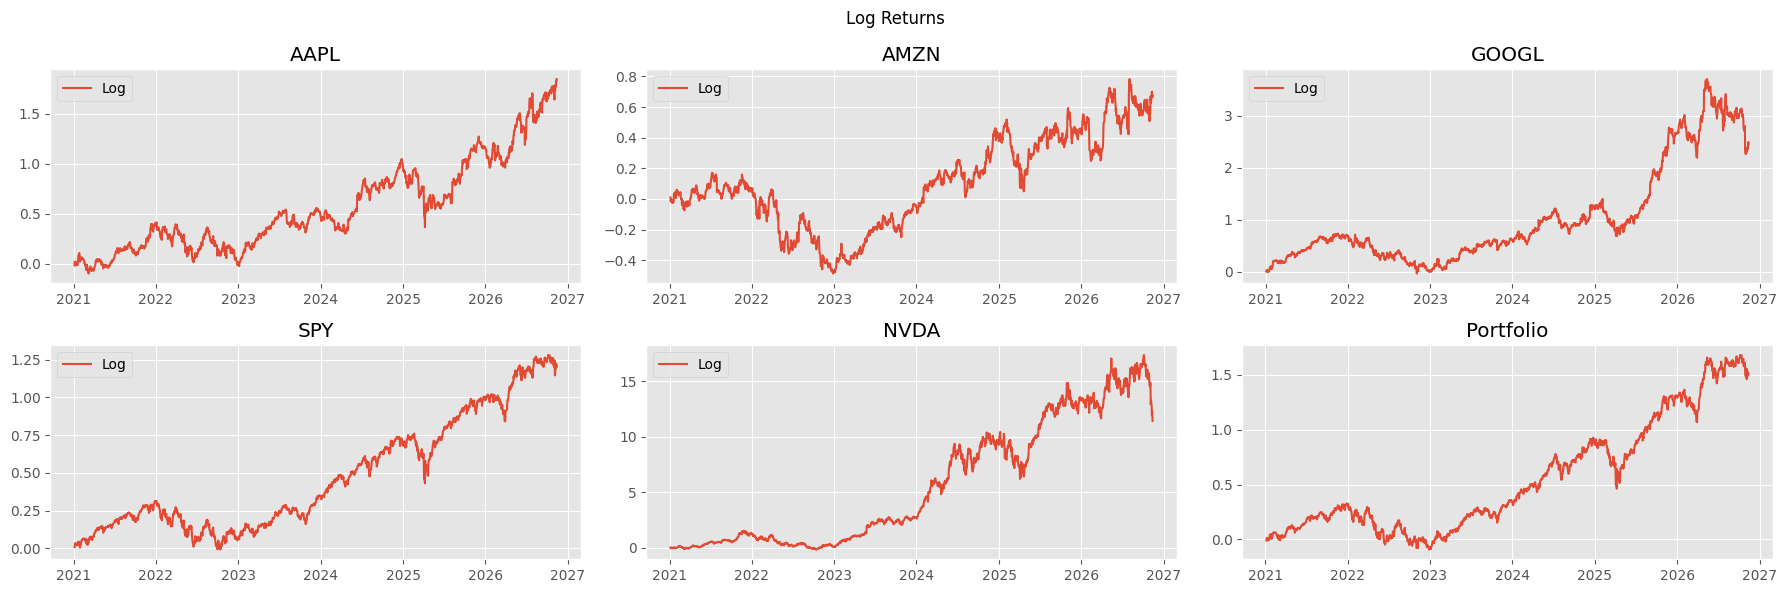

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(18, 6))
axs = axs.flatten()

for i, ticker in enumerate(tickers):
    axs[i].plot(np.exp(df[f'{ticker}_log_ret'].cumsum()) - 1, label='Log')
    axs[i].set_title(f'{ticker}')
    axs[i].legend()

axs[5].plot(np.exp((np.log(df.sum(axis=1) / df.sum(axis=1).shift(1)).dropna()).cumsum()) - 1)
axs[5].set_title('Portfolio')

fig.suptitle('Log Returns')
plt.tight_layout();

### Check Normality of Log Returns

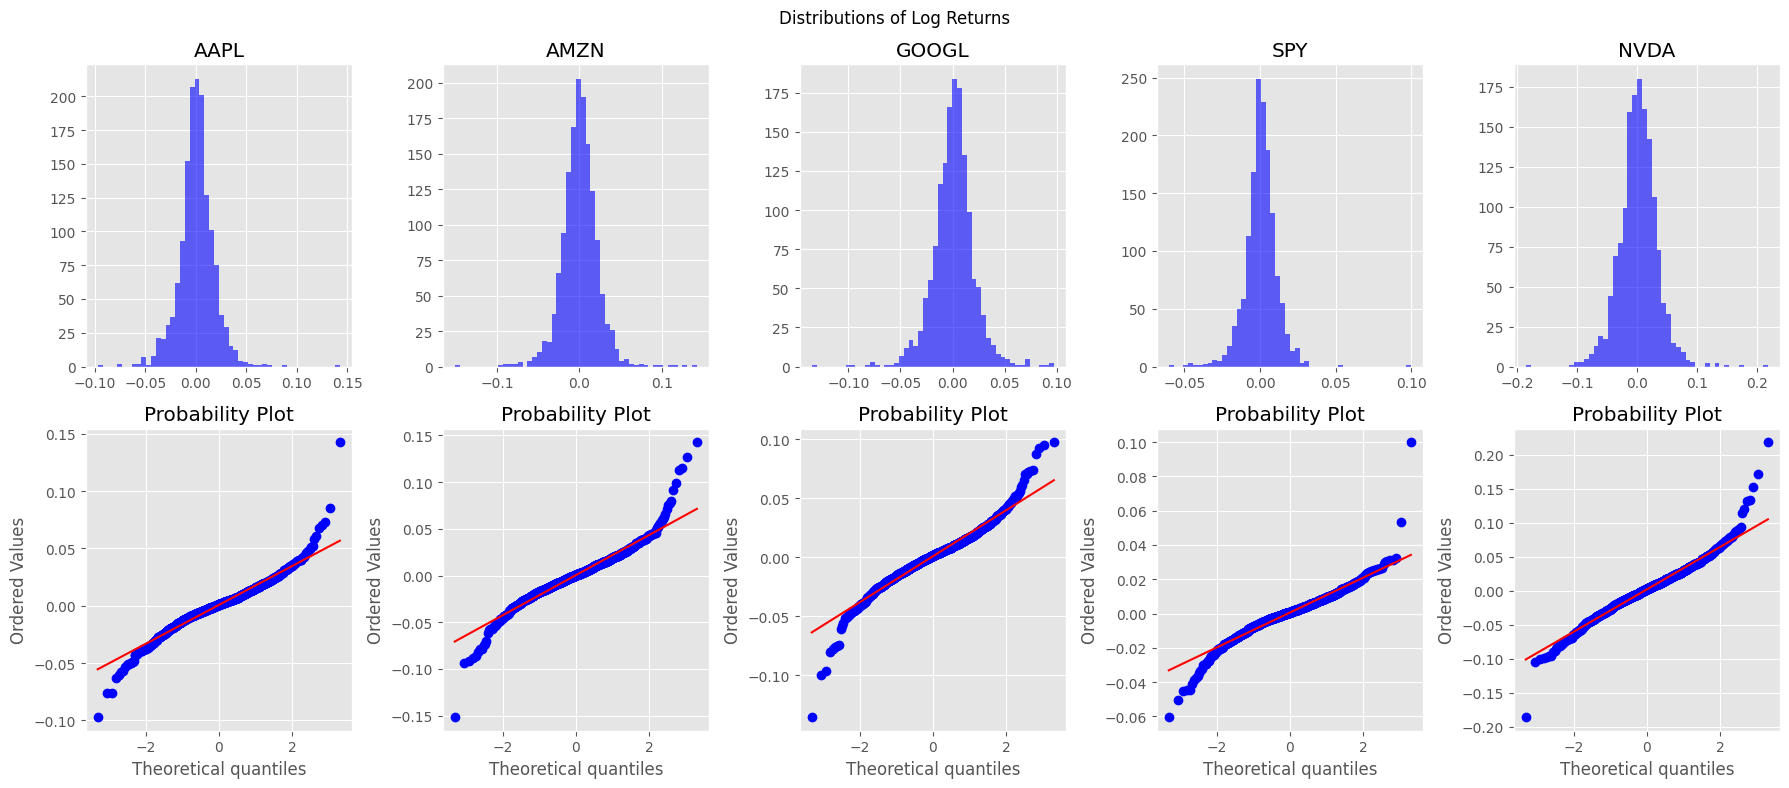

In [8]:
n_tickers = len(tickers)

fig, axs = plt.subplots(2, n_tickers, figsize=(18, 8))
axs = axs.flatten()

for i, ticker in enumerate(tickers):
    axs[i].hist(df[f'{ticker}_log_ret'], bins=50, color='b', alpha=.6)
    axs[i].set_title(ticker)

    stats.probplot(df[f'{ticker}_log_ret'], dist='norm', plot=axs[i+n_tickers]);

plt.suptitle('Distributions of Log Returns')
plt.tight_layout()

In [9]:
log_returns = df[[f'{ticker}_log_ret' for ticker in tickers]].copy()
pd.DataFrame(
    index=tickers,
    data={
        'is normal': stats.jarque_bera(log_returns, axis=0).pvalue > .05,
        'p value': stats.jarque_bera(log_returns, axis=0).pvalue
    }
)


,is normal,p value
AAPL,False,0.000000e+00
AMZN,False,0.000000e+00
GOOGL,False,1.077508e-240
SPY,False,0.000000e+00
NVDA,False,4.040889e-180


## GARCH(1, 1) on Volatility

In [24]:
threshold = df.shape[0] - 20 # need 20 days for forecast
train = df[f'{tickers[0]}_log_ret'].iloc[:threshold]*100
test = df[f'{tickers[0]}_log_ret'].iloc[threshold:]*100

model = arch_model(
    train, vol='Garch',
    p=1, q=1, mean='Constant', dist='t'
)

res = model.fit(disp='off')

res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                        Constant Mean - GARCH Model Results                         
====================================================================================
Dep. Variable:                 AAPL_log_ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -2721.03
Distribution:      Standardized Student's t   AIC:                           5452.05
Method:                  Maximum Likelihood   BIC:                           5478.46
                                              No. Observations:                 1453
Date:                      Fri, Nov 13 2026   Df Residuals:                     1452
Time:                              20:00:21   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1018  3.619e-02      2.814  4.893e-03 [3.091e-02,  0.173]
                              Volatility Model                              
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega          0.0725  3.026e-02      2.397  1.653e-02   [1.322e-02,  0.132]
alpha[1]       0.0634  1.391e-02      4.554  5.257e-06 [3.610e-02,9.063e-02]
beta[1]        0.9139  1.823e-02     50.134      0.000     [  0.878,  0.950]
                              Distribution                              
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
nu             4.8955      0.610      8.028  9.886e-16 [  3.700,  6.091]
========================================================================

Covariance estimator: robust
"""

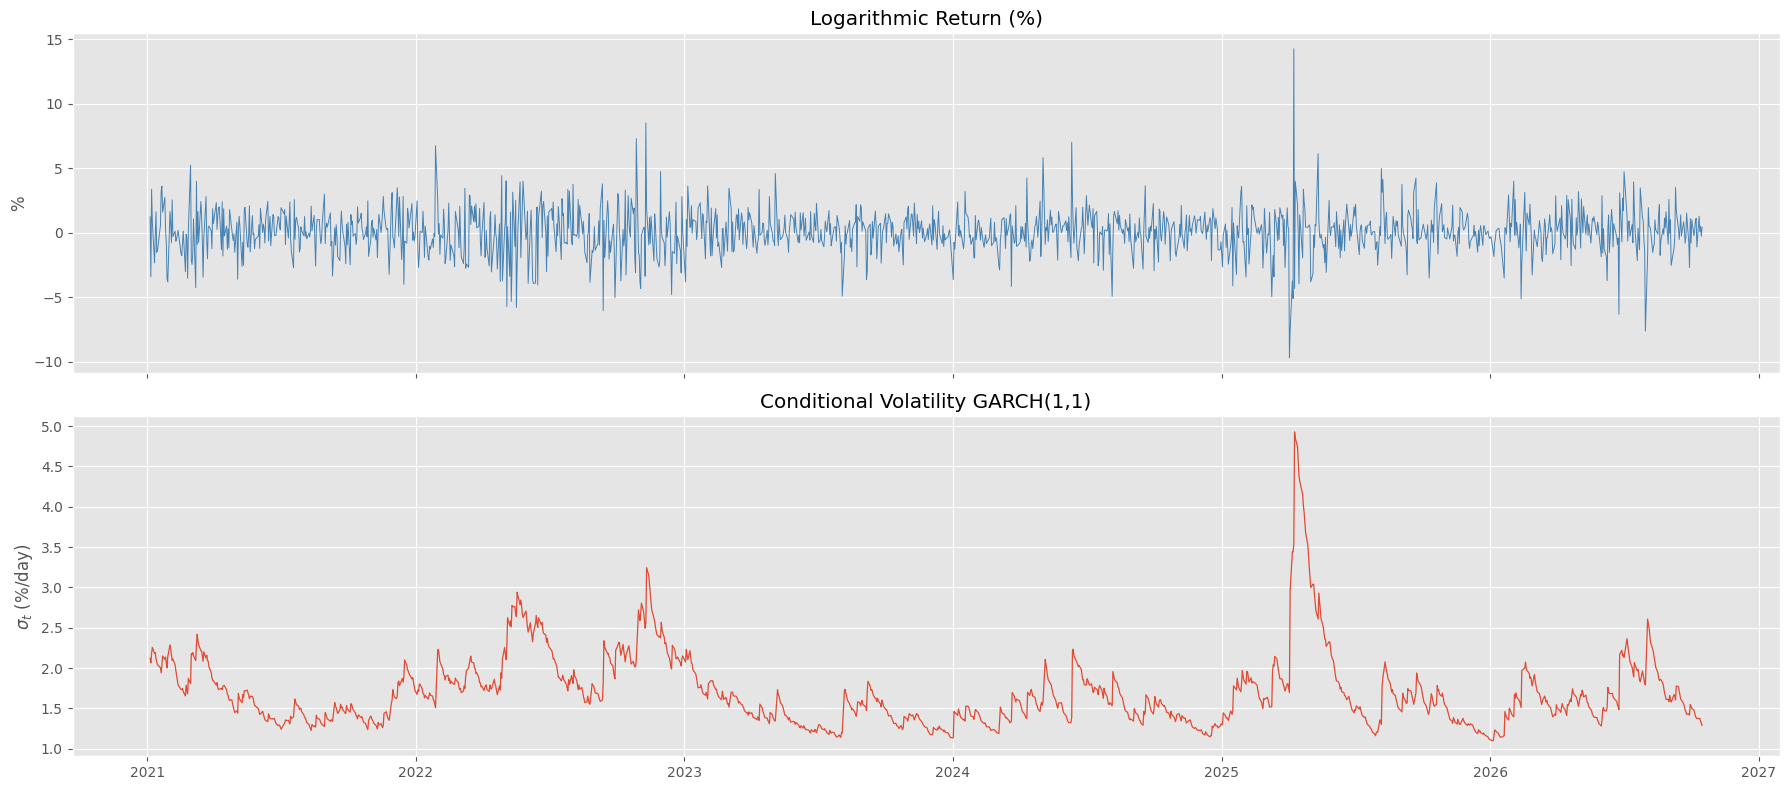

In [25]:
cond_vol = res.conditional_volatility

fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)

axes[0].plot(train.index, train, color='steelblue', linewidth=0.7)
axes[0].set_title('Logarithmic Return (%)')
axes[0].set_ylabel('%')

axes[1].plot(cond_vol.index, cond_vol, linewidth=0.9)
axes[1].set_title('Сonditional Volatility GARCH(1,1)')
axes[1].set_ylabel(r'$\sigma_t$ (%/day)')

plt.tight_layout()

In [26]:
results = {}
fits = {}

for dist_name in ['normal', 't']:
    m = arch_model(train, vol='Garch', p=1, q=1, mean='Constant',
                   dist=dist_name, rescale=True)
    r = m.fit(disp='off')
    fits[dist_name] = r
    results[dist_name] = {
        'Log-Likelihood': r.loglikelihood,
        'AIC': r.aic,
        'BIC': r.bic,
        'Persistence (alpha+beta)': r.params['alpha[1]'] + r.params['beta[1]'],
    }

comparison = pd.DataFrame(results).T
comparison = comparison.astype(float).round(3)
comparison

,Log-Likelihood,AIC,BIC,Persistence (alpha+beta)
normal,-2780.122,5568.244,5589.369,0.968
t,-2721.026,5452.051,5478.458,0.977


### Predict 20 days of volatility

In [27]:
forecast = res.forecast(horizon=len(test))
variance_forecast = forecast.variance.iloc[-1].values

volatility_forecast = np.sqrt(variance_forecast)

real_volatility = np.abs(test)

In [28]:
np.round(real_volatility.mean(), 2), np.round(volatility_forecast.mean(), 2)

(np.float64(1.32), np.float64(1.38))

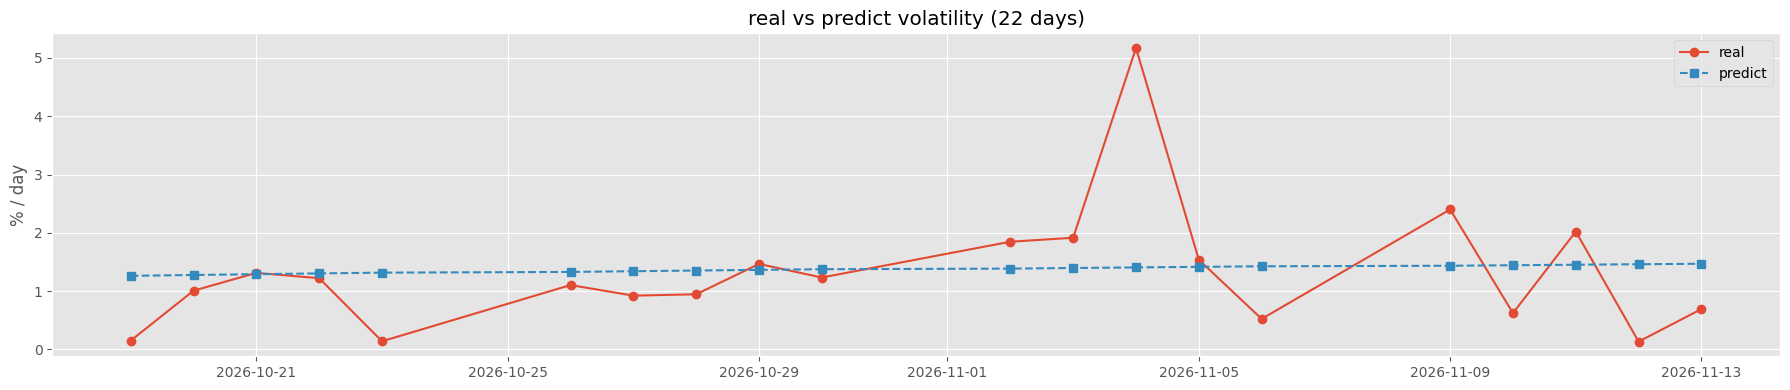

In [29]:
plt.figure(figsize=(18, 4))
plt.plot(real_volatility.index, real_volatility, 'o-', label='real')
plt.plot(real_volatility.index, volatility_forecast, 's--', label='predict')
plt.title('real vs predict volatility (22 days)')
plt.ylabel('% / day')
plt.legend()
plt.tight_layout()